# Step 3: Causal diagram, structural model, scenario analysis
Run Steps 1 and 2 first. Needs `monthly_panel_with_hormuz_state.csv` and `baseline_results.csv` in your `Dataset` folder.

In [ ]:
import pandas as pd, numpy as np
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/My Work/Research/AI+ BBA/Supply Chain_GNN/Dataset'

Mounted at /content/drive


## 1. Causal diagram (dag) and assumptions

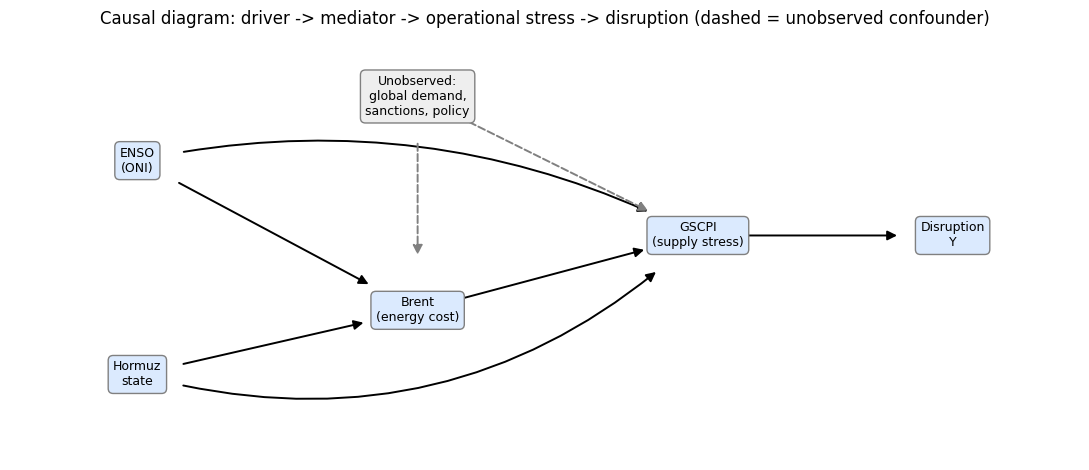

ID                                                                                                 Assumption                        Why it is plausible                                                      Main threat
A1                                                 Hormuz state and ENSO are exogenous to supply-chain stress Plausible for ENSO; Hormuz is geopolitical                              Hormuz data covers one episode only
A2                          Global demand, sanctions and policy are unobserved confounders of Brent and GSCPI                    Shown dashed in the DAG                          Effects of Brent on GSCPI may be biased
A3 Brent mediates part of the Hormuz effect; a direct Hormuz -> GSCPI edge (rerouting, insurance) also exists      Chokepoint mechanism in your proposal Direct and indirect effects cannot be separated with one episode
A4                                                          GSCPI is a valid proxy for operational disruption               Glob

In [ ]:
import matplotlib.pyplot as plt
nodes = {"ENSO\n(ONI)": (0, 1.0), "Hormuz\nstate": (0, -1.0), "Brent\n(energy cost)": (2.2, -0.4),
         "GSCPI\n(supply stress)": (4.4, 0.3), "Disruption\nY": (6.4, 0.3), "Unobserved:\nglobal demand,\nsanctions, policy": (2.2, 1.6)}
edges = [("ENSO\n(ONI)", "Brent\n(energy cost)"), ("ENSO\n(ONI)", "GSCPI\n(supply stress)"),
         ("Hormuz\nstate", "Brent\n(energy cost)"), ("Hormuz\nstate", "GSCPI\n(supply stress)"),
         ("Brent\n(energy cost)", "GSCPI\n(supply stress)"), ("GSCPI\n(supply stress)", "Disruption\nY"),
         ("Unobserved:\nglobal demand,\nsanctions, policy", "Brent\n(energy cost)"),
         ("Unobserved:\nglobal demand,\nsanctions, policy", "GSCPI\n(supply stress)")]
fig, ax = plt.subplots(figsize=(11, 4.8))
direct = {("ENSO\n(ONI)", "GSCPI\n(supply stress)"): -0.18, ("Hormuz\nstate", "GSCPI\n(supply stress)"): 0.28}
for a, b in edges:
    dashed = a.startswith("Unobserved")
    rad = direct.get((a, b), 0.0)
    ax.annotate("", xy=nodes[b], xytext=nodes[a], arrowprops=dict(arrowstyle="-|>", lw=1.4, ls="--" if dashed else "-",
                color="grey" if dashed else "black", shrinkA=34, shrinkB=40, mutation_scale=14,
                connectionstyle=f"arc3,rad={rad}"))
for n, (x, y) in nodes.items():
    ax.text(x, y, n, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", fc="#eeeeee" if n.startswith("Unobserved") else "#dbeafe", ec="grey"))
ax.set_xlim(-1, 7.4); ax.set_ylim(-1.8, 2.2); ax.axis("off")
ax.set_title("Causal diagram: driver -> mediator -> operational stress -> disruption (dashed = unobserved confounder)")
fig.tight_layout(); fig.savefig(f"{BASE}/causal_dag.png", dpi=150); plt.show()

assumptions = pd.DataFrame([
    ["A1", "Hormuz state and ENSO are exogenous to supply-chain stress", "Plausible for ENSO; Hormuz is geopolitical", "Hormuz data covers one episode only"],
    ["A2", "Global demand, sanctions and policy are unobserved confounders of Brent and GSCPI", "Shown dashed in the DAG", "Effects of Brent on GSCPI may be biased"],
    ["A3", "Brent mediates part of the Hormuz effect; a direct Hormuz -> GSCPI edge (rerouting, insurance) also exists", "Chokepoint mechanism in your proposal", "Direct and indirect effects cannot be separated with one episode"],
    ["A4", "GSCPI is a valid proxy for operational disruption", "Global index, not node-level", "Weak proxy for a single country or company"],
    ["A5", "Structural equations are stable between the training years and 2026", "Needed for any scenario", "2026 shock is far outside the historical range"],
    ["A6", "No feedback from GSCPI to Hormuz or ENSO", "Reasonable at monthly scale", "None expected"]],
    columns=["ID", "Assumption", "Why it is plausible", "Main threat"])
print(assumptions.to_string(index=False)); assumptions.to_csv(f"{BASE}/causal_assumptions.csv", index=False)

## 2. Structural equations (dag-restricted, estimated on history)

In [ ]:
import statsmodels.api as sm
p = pd.read_csv(f"{BASE}/monthly_panel_with_hormuz_state.csv")
p["month"] = pd.PeriodIndex(p["month"], freq="M"); p = p.set_index("month").sort_index()
d = pd.DataFrame({"g": p["gscpi"], "lb": np.log(p["brent"]), "oni": p["oni"]})
d["dg"] = d["g"].diff(); d["db"] = d["lb"].diff(); d["oni_l1"] = d["oni"].shift(1)
d["dg_next"] = d["dg"].shift(-1); d["db_next"] = d["db"].shift(-1)

GCOLS, BCOLS = ["dg", "g", "db", "oni_l1"], ["db", "dg", "oni_l1"]
def fit(end):
    s = d.loc["1999-01":end].dropna(subset=GCOLS + ["dg_next", "db_next"])
    mg = sm.OLS(s["dg_next"], sm.add_constant(s[GCOLS])).fit()
    mb = sm.OLS(s["db_next"], sm.add_constant(s[BCOLS])).fit()
    res = np.column_stack([mg.resid.values, mb.resid.values])
    return mg, mb, res
mg, mb, res = fit("2021-12")
print("\nGSCPI equation (fit to 2021):"); print(mg.params.round(3).to_dict(), "R2", round(mg.rsquared, 3))
print("p-values:", mg.pvalues.round(3).to_dict())
print("Brent equation:", mb.params.round(3).to_dict(), "R2", round(mb.rsquared, 3))


GSCPI equation (fit to 2021):
{'const': 0.008, 'dg': 0.087, 'g': -0.06, 'db': 0.075, 'oni_l1': -0.017} R2 0.022
p-values: {'const': 0.719, 'dg': 0.173, 'g': 0.018, 'db': 0.72, 'oni_l1': 0.555}
Brent equation: {'const': 0.005, 'db': 0.219, 'dg': 0.004, 'oni_l1': -0.015} R2 0.071


## 3. Simulation: probability of disruption from the structural model

In [ ]:
rng = np.random.default_rng(0)
def simulate(row, h, mg, mb, res, n=400, do_db=None, beta_override=None):
    """Simulate h months ahead from the state in `row`. do_db = {step: forced Brent log-change} (do-operator)."""
    g, dg, db, oni = row["g"], row["dg"], row["db"], row["oni_l1"]
    idx = rng.integers(0, len(res), size=(n, h))
    G = np.full(n, g); DG = np.full(n, dg); DB = np.full(n, db); best = np.full(n, -np.inf)
    for k in range(h):
        e = res[idx[:, k]]
        bcoef = mg.params["db"] if beta_override is None else beta_override
        dg_new = (mg.params["const"] + mg.params["dg"] * DG + mg.params["g"] * G + bcoef * DB
                  + mg.params["oni_l1"] * oni + e[:, 0])
        db_new = mb.params["const"] + mb.params["db"] * DB + mb.params["dg"] * DG + mb.params["oni_l1"] * oni + e[:, 1]
        if do_db is not None and k in do_db: db_new = np.full(n, do_db[k])      # cut incoming edges, set Brent
        G = G + dg_new; DG, DB = dg_new, db_new
        best = np.maximum(best, G - g)
    return best   # largest rise in GSCPI over the horizon, per simulated path

## 4. Validation: causal-aware model vs the two baselines (same time split)

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
rows = []
for h in (1, 2, 3):
    y = p[f"y_gscpi_h{h}"]
    for sp, (a, b) in {"valid": ("2019-01", "2021-12"), "test": ("2022-01", "2025-12")}.items():
        sub = d.loc[a:b].dropna(subset=["dg", "g", "db", "oni_l1"]); sub = sub[y.reindex(sub.index).notna()]
        prob = [np.mean(simulate(r, h, mg, mb, res, n=300) >= 0.5) for _, r in sub.iterrows()]
        yy = y.reindex(sub.index).values
        if len(set(yy)) > 1:
            rows.append(dict(target=f"y_gscpi_h{h}", model="causal_structural", split=sp, n=len(sub), pos_rate=round(yy.mean(), 2),
                             auc=round(roc_auc_score(yy, prob), 3), avg_precision=round(average_precision_score(yy, prob), 3)))
cres = pd.DataFrame(rows)
try:
    base = pd.read_csv(f"{BASE}/baseline_results.csv"); base = base[base.target.str.startswith("y_gscpi")]
    cmp_ = pd.concat([base, cres]).sort_values(["target", "split", "model"]); print("\n", cmp_.to_string(index=False))
    cmp_.to_csv(f"{BASE}/model_comparison.csv", index=False)
except FileNotFoundError:
    print(cres.to_string(index=False))


     target             model split  n  pos_rate   auc  avg_precision
y_gscpi_h1 causal_structural  test 48      0.08 0.568          0.123
y_gscpi_h1        grad_boost  test 48      0.08 0.767          0.402
y_gscpi_h1          logistic  test 48      0.08 0.608          0.170
y_gscpi_h1 causal_structural valid 36      0.25 0.397          0.289
y_gscpi_h1        grad_boost valid 36      0.25 0.560          0.318
y_gscpi_h1          logistic valid 36      0.25 0.514          0.455
y_gscpi_h2 causal_structural  test 48      0.23 0.590          0.283
y_gscpi_h2        grad_boost  test 48      0.23 0.813          0.696
y_gscpi_h2          logistic  test 48      0.23 0.656          0.360
y_gscpi_h2 causal_structural valid 36      0.42 0.522          0.490
y_gscpi_h2        grad_boost valid 36      0.42 0.410          0.378
y_gscpi_h2          logistic valid 36      0.42 0.521          0.563
y_gscpi_h3 causal_structural  test 48      0.27 0.707          0.579
y_gscpi_h3        grad_boost  te

## 5. Scenario analysis: do(brent shock) from feb 2026

In [ ]:
mg2, mb2, res2 = fit("2025-12")                                   # all pre-2026 history
row0 = d.loc[pd.Period("2026-02", freq="M")].copy()
row0["oni_l1"] = d["oni"].dropna().iloc[-1]                       # last known ONI held fixed (ONI is missing after Apr 2026)
shock_obs = float(np.log(103.13 / 70.89))                          # Brent change actually seen in Mar 2026
beta_event = float((p.loc["2026-04", "gscpi"] - p.loc["2026-02", "gscpi"]) / np.log(p.loc["2026-04", "brent"] / p.loc["2026-02", "brent"]))
print("\nBrent log-shock seen in Mar 2026:", round(shock_obs, 3), "| event-calibrated beta (n=1):", round(beta_event, 2),
      "| historical beta:", round(mg2.params["db"], 3))
scen = {"Baseline": {0: 0.0}, "Moderate (+20%)": {0: float(np.log(1.2))},
        "Severe (as Mar 2026)": {0: shock_obs},
        "Recovery (shock then reversal)": {0: shock_obs, 1: -0.25, 2: -0.15}}
out = []
for name, dob in scen.items():
    for calib, beta in {"historical": None, "event-calibrated": beta_event}.items():
        r = simulate(row0, 3, mg2, mb2, res2, n=4000, do_db=dob, beta_override=beta)
        out.append(dict(scenario=name, calibration=calib, P_rise_ge_0_5_within_3m=round(float((r >= 0.5).mean()), 3),
                        mean_max_gscpi_rise=round(float(r.mean()), 2)))
scen_df = pd.DataFrame(out)
b0 = scen_df[scen_df.scenario == "Baseline"].set_index("calibration")["P_rise_ge_0_5_within_3m"]
scen_df["delta_vs_baseline"] = scen_df.apply(lambda r: round(r["P_rise_ge_0_5_within_3m"] - b0[r["calibration"]], 3), axis=1)
print(scen_df.to_string(index=False)); scen_df.to_csv(f"{BASE}/scenario_matrix.csv", index=False)
print("\nObserved: GSCPI rose", round(p.loc['2026-04','gscpi'] - p.loc['2026-02','gscpi'], 2), "between Feb and Apr 2026.")


Brent log-shock seen in Mar 2026: 0.375 | event-calibrated beta (n=1): 2.57 | historical beta: 0.161
                      scenario      calibration  P_rise_ge_0_5_within_3m  mean_max_gscpi_rise  delta_vs_baseline
                      Baseline       historical                    0.222                 0.19              0.000
                      Baseline event-calibrated                    0.328                 0.36              0.000
               Moderate (+20%)       historical                    0.229                 0.19              0.007
               Moderate (+20%) event-calibrated                    0.683                 0.79              0.355
          Severe (as Mar 2026)       historical                    0.243                 0.22              0.021
          Severe (as Mar 2026) event-calibrated                    0.923                 1.34              0.595
Recovery (shock then reversal)       historical                    0.236                 0.21              